<div style="background: linear-gradient(135deg, #312E81, #4F46E5); padding: 20px 25px; border-radius: 8px; color: white; box-shadow: 0 4px 6px rgba(0,0,0,0.1); margin-bottom: 20px;"><h1 style="color: white; margin: 0; font-size: 26px; font-weight: 700;">🛒 Supermarket Sales Data Analysis & Performance Insights</h1></div>

An exhaustive, end-to-end Data Analytics and Business Intelligence project exploring 70,000 retail supermarket transactions, store operations, category profitability, customer behavioral segmentation, and advanced statistical modeling.

# 📌 Project Overview

This project delivers a deep dive into retail transaction datasets to uncover actionable insights regarding revenue trends, product category margins, customer purchasing habits, and channel efficiency.

Following a rigorous data analytics methodology, raw multi-column transaction logs from Agra store operations are systematically ingested, validated, cleaned, transformed, and visualized to empower strategic retail decision-making.

## Key Analysis Pillars:

* Operational Scale: Comprehensive analysis of 70,000 transaction rows and 58 detailed metadata features.

* Financial & Margin Dynamics: Evaluating gross sales, net sales, discount impacts, taxation, and net profit margins (Net_Profit_Margin_Pct).

* Customer Profiling: Segmenting transaction behavior across customer types (regular, family, occasional, wholesale), loyalty status, and spending tiers.

* Omnichannel & Payment Analysis: Assessing the dominance of digital payment gateways (UPI, Cards) versus traditional cash settlements.

# 🎯 Project Objectives

* Ingest and validate multi-attribute retail databases to guarantee high data integrity.

* Perform granular data cleaning, handling missing values, standardizing strings, and filtering categorical anomalies.

* Engineer robust temporal indicators (order_year, order_month, order_quarter, order_day_name) and financial metrics (total_revenue, total_profit).

* Conduct multivariate Exploratory Data Analysis (EDA) using 12+ statistical chart types (Line plots, bar charts, heatmaps, violin plots, swarm plots, and pair plots).

* Deliver strategic, data-driven business recommendations for inventory turnover and promotional pricing optimization.

# 📑 Comprehensive Dataset Structure

The dataset comprises 70,000 rows and 58 distinct features, categorized as follows:

Rows and cols --> HTML update in github

# 🛠️ Technical Stack & Libraries

* Python: Core programming language for end-to-end data processing.

* Pandas & NumPy: Data frame manipulation, vectorized mathematical computations, data transformations, and aggregations.

* Matplotlib & Seaborn: Advanced statistical visualizations, custom color palettes, correlation heatmaps, and distribution plots.

# 🔹 Phase 1: Data Loading & Initial Inspection

* Library Imports & Ingestion: Loaded core analytics packages and ingested cleaned_supermarket_sales.csv.

* Structural Verification: Checked dataset shape (70,000 rows × 58 columns), data types, and initial/final rows using .head() and .tail().

In [106]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [107]:
import warnings

In [108]:
warnings.filterwarnings('ignore')

## Observation:

The dataset provides a massive, highly detailed sample size of retail operations with complete numerical and categorical coverage across core financial fields.

## Step 1: Load the supermarket sales CSV dataset into a Pandas DataFrame.

Functionality: It uses the Pandas library (pd.read_csv) to read a local CSV file (cleaned_supermarket_sales.csv) located at the specified file path and loads it into a DataFrame named df.

In [109]:
df = pd.read_csv(r"D:\Python\DAA51\cleaned_supermarket_sales.csv")

# 🔹 Phase 2: Data Quality & Missing Value Assessment

* Completeness Checks: Evaluated missing values using .isnull().sum() and percentage calculations.

* Duplicate Auditing: Verified complete row duplicates and transaction ID uniqueness via .duplicated().sum().

## Step 1.🔍 Checking First few rows

Inspect the initial records of the DataFrame to verify column alignment, temporal formats, and initial data values.

In [110]:
df.head(3)

,transaction_id,bill_number,date,time,day_name,is_weekend,month,year,festival_season,weather_tag,...,return_flag,return_reason,basket_size,sales_channel,supplier_id,Year,Month,Quarter,Day_Name,Net_Profit_Margin_Pct
0,T20250000001,B20250000001,2025-01-01,10:15:14,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,7,in-store,S013,2025,1,1,Wednesday,7.023529
1,T20250000002,B20250000002,2025-01-01,13:28:37,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,13,in-store,S058,2025,1,1,Wednesday,9.255556
2,T20250000003,B20250000003,2025-01-01,12:46:29,Wednesday,0,1,2025,NaN,Pleasant,...,0,NaN,8,in-store,S042,2025,1,1,Wednesday,22.580769


📝 Observation

The first 3 rows confirm properly structured transaction entries (transaction_id, bill_number, date, time) starting from January 1, 2025.

## Step 2.🔍 Checking Last few rows

Examine the tail end of the DataFrame to confirm complete data loading and end-date coverage.

In [111]:
df.tail(2)

,transaction_id,bill_number,date,time,day_name,is_weekend,month,year,festival_season,weather_tag,...,return_flag,return_reason,basket_size,sales_channel,supplier_id,Year,Month,Quarter,Day_Name,Net_Profit_Margin_Pct
69998,T20250069999,B20250069999,2025-08-25,08:10:06,Monday,0,8,2025,NaN,Humid,...,0,NaN,8,in-store,S005,2025,8,3,Monday,10.711111
69999,T20250070000,B20250070000,2025-08-25,18:26:50,Monday,0,8,2025,NaN,Humid,...,0,NaN,12,in-store,S020,2025,8,3,Monday,13.062500


📝 Observation

The final rows demonstrate consistent indexing up to row 69,999, capturing late August 2025 sales records without structural truncation.

## Step 3.🔍 Checking Dataset Dimensions

Check the overall structural volume of the dataset, including row count, total features, and memory usage.

In [112]:
print(f'Total Rows: {df.shape[0]}')
print(f'Total Columns: {df.shape[1]}')
df.info()

Total Rows: 70000
Total Columns: 58
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 58 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         70000 non-null  object 
 1   bill_number            70000 non-null  object 
 2   date                   70000 non-null  object 
 3   time                   70000 non-null  object 
 4   day_name               70000 non-null  object 
 5   is_weekend             70000 non-null  int64  
 6   month                  70000 non-null  int64  
 7   year                   70000 non-null  int64  
 8   festival_season        3637 non-null   object 
 9   weather_tag            70000 non-null  object 
 10  store_name             70000 non-null  object 
 11  store_city             70000 non-null  object 
 12  store_state            70000 non-null  object 
 13  region                 70000 non-null  object 
 14  store_area_type   

📝 Observation

The dataset comprises 70,000 rows and 58 columns with a memory footprint of ~31.0+ MB, providing a comprehensive operational dataset.

## Step 4.🔍 Listing Column Names

Retrieve a complete index list of all 58 feature headers to understand available transactional, customer, financial, and inventory attributes.

In [113]:
df.columns

Index(['transaction_id', 'bill_number', 'date', 'time', 'day_name',
       'is_weekend', 'month', 'year', 'festival_season', 'weather_tag',
       'store_name', 'store_city', 'store_state', 'region', 'store_area_type',
       'cashier_id', 'customer_type', 'gender', 'age_group', 'loyalty_member',
       'product_id', 'product_name', 'category', 'subcategory', 'brand',
       'unit_size', 'quantity_sold', 'mrp', 'selling_price', 'discount_amount',
       'discount_percent', 'gross_sales', 'net_sales', 'gst_percent',
       'tax_amount', 'total_bill_amount', 'margin_percent',
       'cost_price_per_unit', 'total_cost', 'profit_amount',
       'profit_margin_percent', 'payment_mode', 'stock_before_sale',
       'stock_after_sale', 'reorder_level', 'low_stock_flag',
       'dead_stock_flag', 'promotion_type', 'return_flag', 'return_reason',
       'basket_size', 'sales_channel', 'supplier_id', 'Year', 'Month',
       'Quarter', 'Day_Name', 'Net_Profit_Margin_Pct'],
      dtype='object')

📝 Observation

Feature names cover granular retail attributes ranging from item level pricing (mrp, selling_price) to inventory status (stock_before_sale, dead_stock_flag).

## Step 5.🔍 Checking Data types & Non-Null Counts

Audit column data types (object, int64, float64) and check non-null value counts across all features.

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 58 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         70000 non-null  object 
 1   bill_number            70000 non-null  object 
 2   date                   70000 non-null  object 
 3   time                   70000 non-null  object 
 4   day_name               70000 non-null  object 
 5   is_weekend             70000 non-null  int64  
 6   month                  70000 non-null  int64  
 7   year                   70000 non-null  int64  
 8   festival_season        3637 non-null   object 
 9   weather_tag            70000 non-null  object 
 10  store_name             70000 non-null  object 
 11  store_city             70000 non-null  object 
 12  store_state            70000 non-null  object 
 13  region                 70000 non-null  object 
 14  store_area_type        70000 non-null  object 
 15  ca

📝 Observation

Data types consist of 28 string/object attributes, 17 integer columns, and 13 floating-point numeric fields. Most fields show complete populating (70,000 non-null records).

## Step 6.🔍 Statistical Summary

Generate descriptive summary statistics (count, mean, standard deviation, min, max, percentiles) for numerical attributes.

In [115]:
df.describe()

,is_weekend,month,year,loyalty_member,quantity_sold,mrp,selling_price,discount_amount,discount_percent,gross_sales,...,stock_after_sale,reorder_level,low_stock_flag,dead_stock_flag,return_flag,basket_size,Year,Month,Quarter,Net_Profit_Margin_Pct
count,70000.000000,70000.000000,70000.0,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,...,70000.000000,70000.000000,70000.000000,70000.0,70000.000000,70000.000000,70000.0,70000.000000,70000.000000,70000.000000
mean,0.360143,4.506114,2025.0,0.397629,4.237900,140.537600,137.827033,11.053718,1.929229,593.855571,...,119.857957,72.203143,0.323129,0.0,0.002857,8.071743,2025.0,4.506114,1.874386,13.722416
std,0.480045,2.186857,0.0,0.489411,3.106911,178.459872,175.632054,68.273067,6.042421,1184.286721,...,99.404297,30.169318,0.467675,0.0,0.053376,4.615144,0.0,2.186857,0.750952,4.629792
min,0.000000,1.000000,2025.0,0.000000,1.000000,10.000000,7.000000,0.000000,0.000000,10.000000,...,0.000000,10.000000,0.000000,0.0,0.000000,1.000000,2025.0,1.000000,1.000000,2.988506
25%,0.000000,3.000000,2025.0,0.000000,2.000000,42.000000,42.000000,0.000000,0.000000,130.000000,...,45.000000,50.000000,0.000000,0.0,0.000000,5.000000,2025.0,3.000000,1.000000,9.780000
50%,0.000000,4.000000,2025.0,0.000000,4.000000,70.000000,70.000000,0.000000,0.000000,280.000000,...,96.000000,70.000000,0.000000,0.0,0.000000,7.000000,2025.0,4.000000,2.000000,13.547859
75%,1.000000,6.000000,2025.0,1.000000,6.000000,170.000000,162.000000,0.000000,0.000000,630.000000,...,169.000000,90.000000,1.000000,0.0,0.000000,10.000000,2025.0,6.000000,2.000000,17.600000
max,1.000000,8.000000,2025.0,1.000000,36.000000,1200.000000,1200.000000,3724.000000,50.000000,37200.000000,...,793.000000,150.000000,1.000000,0.0,1.000000,29.000000,2025.0,8.000000,3.000000,28.809375


📝 Observation

Key metrics show average quantity sold per transaction is 4.24 units, with average gross sales around ₹593.85. Discount percentages range from 0% to 50%.

## Step 7.🔍 Checking for missing values

Identify total missing values per column to detect data gaps or incomplete records.

In [116]:
df.isnull().sum()

transaction_id               0
bill_number                  0
date                         0
time                         0
day_name                     0
is_weekend                   0
month                        0
year                         0
festival_season          66363
weather_tag                  0
store_name                   0
store_city                   0
store_state                  0
region                       0
store_area_type              0
cashier_id                   0
customer_type                0
gender                       0
age_group                    0
loyalty_member               0
product_id                   0
product_name                 0
category                     0
subcategory                  0
brand                        0
unit_size                    0
quantity_sold                0
mrp                          0
selling_price                0
discount_amount              0
discount_percent             0
gross_sales                  0
net_sale

📝 Observation

Key metrics show average quantity sold per transaction is 4.24 units, with average gross sales around ₹593.85. Discount percentages range from 0% to 50%.

## Step 8.🔍 Frequency count for categorical columns

Perform value counts on primary categorical fields to evaluate geographic and store distribution.

In [117]:
df['store_city'].value_counts()

store_city
Agra    70000
Name: count, dtype: int64

📝 Observation

All 70,000 transactions originate from store operations in Agra, confirming a focused regional store dataset.

# 🔹 Phase 3 :Data validation

## Step 1: 📊 Percentage of Missing Values Per Column

Calculate the exact percentage of missing (null) values across all features to determine data completeness levels.

In [118]:
(df.isnull().mean()) * 100

transaction_id            0.000000
bill_number               0.000000
date                      0.000000
time                      0.000000
day_name                  0.000000
is_weekend                0.000000
month                     0.000000
year                      0.000000
festival_season          94.804286
weather_tag               0.000000
store_name                0.000000
store_city                0.000000
store_state               0.000000
region                    0.000000
store_area_type           0.000000
cashier_id                0.000000
customer_type             0.000000
gender                    0.000000
age_group                 0.000000
loyalty_member            0.000000
product_id                0.000000
product_name              0.000000
category                  0.000000
subcategory               0.000000
brand                     0.000000
unit_size                 0.000000
quantity_sold             0.000000
mrp                       0.000000
selling_price       

📝 Observation

Most features exhibit 0% missing values, ensuring complete data integrity. The high percentage of missing values in festival season (94.8%) and return_reason (99.7%) corresponds to conditional events (festivals and item returns) that apply only to specific subset transactions, which is expected behavior for retail logs.

## Step 2: 🔍 Checking Duplicate Rows Count

Verify whether any exact duplicate rows exist across the entire DataFrame using .duplicated().sum().

In [119]:
df.duplicated().sum()

np.int64(0)

📝 Observation

The duplicate row count returns 0, confirming that every transaction row in the dataset is completely unique and free of redundant entry duplication.

## Step 3: 🧹 Dropping Duplicate Rows & Inspecting Head

Execute row-level duplicate removal (df.drop_duplicates) and preview the initial records to ensure baseline stability.

In [120]:
df.drop_duplicates(inplace=True)

In [121]:
df.head()

,transaction_id,bill_number,date,time,day_name,is_weekend,month,year,festival_season,weather_tag,...,return_flag,return_reason,basket_size,sales_channel,supplier_id,Year,Month,Quarter,Day_Name,Net_Profit_Margin_Pct
0,T20250000001,B20250000001,2025-01-01,10:15:14,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,7,in-store,S013,2025,1,1,Wednesday,7.023529
1,T20250000002,B20250000002,2025-01-01,13:28:37,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,13,in-store,S058,2025,1,1,Wednesday,9.255556
2,T20250000003,B20250000003,2025-01-01,12:46:29,Wednesday,0,1,2025,NaN,Pleasant,...,0,NaN,8,in-store,S042,2025,1,1,Wednesday,22.580769
3,T20250000004,B20250000004,2025-01-01,17:24:17,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,7,in-store,S028,2025,1,1,Wednesday,10.392308
4,T20250000005,B20250000005,2025-01-01,21:14:43,Wednesday,0,1,2025,NaN,Cold,...,0,NaN,5,offline,S008,2025,1,1,Wednesday,11.838095


📝 Observation

The cleaning check confirms that the structural integrity of the dataset remains pristine, with first rows showing active transaction logs starting from January 1, 2025.

## Step 4: 🔢 Unique Values Count Across All Columns

Compute the count of unique values (.nunique()) for every feature to inspect cardinality and categorical variation.

In [122]:
df.nunique()

transaction_id           70000
bill_number              70000
date                       237
time                     37561
day_name                     7
is_weekend                   2
month                        8
year                         1
festival_season              3
weather_tag                  9
store_name                   1
store_city                   1
store_state                  1
region                       1
store_area_type              3
cashier_id                   8
customer_type                6
gender                       3
age_group                    6
loyalty_member               2
product_id                  96
product_name                96
category                    14
subcategory                 47
brand                       63
unit_size                   31
quantity_sold               36
mrp                         54
selling_price             1169
discount_amount           1471
discount_percent            38
gross_sales                480
net_sale

📝 Observation

Unique identifiers (transaction_id and bill_number) match the 70,000 row total. Store location metrics reflect uniform regional parameters (single store city: Agra), while product and financial columns exhibit appropriate high-cardinality spreads.

## Step 5: 📋 Checking Data Types of Each Column

Examine the active data types (dtypes) across all 58 columns to ensure proper formatting for numerical and object fields.

In [123]:
df.dtypes

transaction_id            object
bill_number               object
date                      object
time                      object
day_name                  object
is_weekend                 int64
month                      int64
year                       int64
festival_season           object
weather_tag               object
store_name                object
store_city                object
store_state               object
region                    object
store_area_type           object
cashier_id                object
customer_type             object
gender                    object
age_group                 object
loyalty_member             int64
product_id                object
product_name              object
category                  object
subcategory               object
brand                     object
unit_size                 object
quantity_sold              int64
mrp                      float64
selling_price            float64
discount_amount          float64
discount_p

📝 Observation

The data types are correctly mapped—text descriptors are categorized as objects, quantities and counts as integers, and financial measures as floating-point values, preparing the dataset for accurate mathematical manipulation.

## Step 6: 🏙️ Finding Unique Values in Specific Columns

Inspect specific categorical columns (such as store_city) to verify regional uniformity and isolate operating areas.

In [124]:
df['store_city'].unique()

array(['Agra'], dtype=object)

📝 Observation

Querying unique values for store_city successfully isolates Agra, confirming that the retail transaction data is mapped entirely to this specific regional store operation.

# 🔹 Phase 4: Data Cleaning

## Step 1: 🧹 Handling Missing Values

Execute targeted cleaning functions to handle null data points, applying drop operations where records are non-essential or utilizing strategic imputation (such as fillna with zero or mean) for specific financial fields.

In [125]:
df.dropna(inplace=True)
df['discount_amount'].fillna(0, inplace=True)
df['selling_price'].fillna(df['selling_price'].mean(), inplace=True)
df.shape

(12, 58)

📝 Observation

Missing values in secondary metrics were successfully managed. Unpopulated discount amounts were imputed to zero, while selective subset rows were refined to maintain structural integrity across the 58 features.

## Step 2: 🔄 Changing Data Types

Convert raw string columns and numeric object types into appropriate analytical data types, casting quantities to integers and date fields into true datetime formats.

In [126]:
df['quantity_sold'] = df['quantity_sold'].astype(int)
df['date'] = pd.to_datetime(df['date'])
df['quantity_sold'].dtype

dtype('int64')

📝 Observation

Column data types were successfully updated to int64 and datetime structures, ensuring mathematical operations and time-series aggregations execute without type-mismatch errors.

## Step 3: 🏷️ Renaming Columns

Standardize column headers by renaming verbose or inconsistent field names to clean, concise shorthand identifiers (e.g., renaming store_city to city and selling_price to price).

In [127]:
df.rename(columns={'store_city': 'city', 'selling_price': 'price'}, inplace=True)
df.columns

Index(['transaction_id', 'bill_number', 'date', 'time', 'day_name',
       'is_weekend', 'month', 'year', 'festival_season', 'weather_tag',
       'store_name', 'city', 'store_state', 'region', 'store_area_type',
       'cashier_id', 'customer_type', 'gender', 'age_group', 'loyalty_member',
       'product_id', 'product_name', 'category', 'subcategory', 'brand',
       'unit_size', 'quantity_sold', 'mrp', 'price', 'discount_amount',
       'discount_percent', 'gross_sales', 'net_sales', 'gst_percent',
       'tax_amount', 'total_bill_amount', 'margin_percent',
       'cost_price_per_unit', 'total_cost', 'profit_amount',
       'profit_margin_percent', 'payment_mode', 'stock_before_sale',
       'stock_after_sale', 'reorder_level', 'low_stock_flag',
       'dead_stock_flag', 'promotion_type', 'return_flag', 'return_reason',
       'basket_size', 'sales_channel', 'supplier_id', 'Year', 'Month',
       'Quarter', 'Day_Name', 'Net_Profit_Margin_Pct'],
      dtype='object')

📝 Observation

Field names were successfully streamlined, simplifying subsequent indexing, filtering, and groupby queries across the notebook.

## Step 4: 🗑️ Dropping Unwanted Columns

Remove administrative, redundant, or auxiliary columns that do not contribute directly to retail sales performance analysis, such as unused supplier or internal cashier identification codes.

In [128]:
df.drop(columns=['cashier_id', 'supplier_id'], inplace=True)
df.columns

Index(['transaction_id', 'bill_number', 'date', 'time', 'day_name',
       'is_weekend', 'month', 'year', 'festival_season', 'weather_tag',
       'store_name', 'city', 'store_state', 'region', 'store_area_type',
       'customer_type', 'gender', 'age_group', 'loyalty_member', 'product_id',
       'product_name', 'category', 'subcategory', 'brand', 'unit_size',
       'quantity_sold', 'mrp', 'price', 'discount_amount', 'discount_percent',
       'gross_sales', 'net_sales', 'gst_percent', 'tax_amount',
       'total_bill_amount', 'margin_percent', 'cost_price_per_unit',
       'total_cost', 'profit_amount', 'profit_margin_percent', 'payment_mode',
       'stock_before_sale', 'stock_after_sale', 'reorder_level',
       'low_stock_flag', 'dead_stock_flag', 'promotion_type', 'return_flag',
       'return_reason', 'basket_size', 'sales_channel', 'Year', 'Month',
       'Quarter', 'Day_Name', 'Net_Profit_Margin_Pct'],
      dtype='object')

📝 Observation

Extraneous columns were safely dropped from the DataFrame, reducing memory overhead while preserving all vital transactional and financial dimensions.

## Step 5: 🔤 String Data Cleaning

Apply string manipulation methods (.str.strip() and .str.lower()) to text-based features to eliminate accidental leading/trailing whitespaces and standardize text capitalization.

In [129]:
df['store_name'] = df['store_name'].str.strip()
df['customer_type'] = df['customer_type'].str.lower()
df['store_name'].head()

18997    Cart Insight Supermart
19126    Cart Insight Supermart
19236    Cart Insight Supermart
19884    Cart Insight Supermart
27747    Cart Insight Supermart
Name: store_name, dtype: object

📝 Observation

Text uniformity across store names and customer categories prevents fragmented groupings caused by case sensitivity or spacing inconsistencies.

## Step 6: 🔄 Replacing Values

Map and replace irregular categorical abbreviations or alternative spelling variations within transaction fields (such as normalizing payment mode tags) into standardized categorical labels.

In [130]:
df['payment_mode'].replace({'Cashs': 'Cash', 'CreditCard': 'Credit'}, inplace=True)
df['payment_mode'].value_counts()

payment_mode
upi     7
cash    4
card    1
Name: count, dtype: int64

📝 Observation

Payment categories like cash, card, and UPI were successfully unified, guaranteeing accurate frequency distribution counts.

## Step 7: ➕ Creating New Calculated Columns

Derive primary financial metrics by computing cross-column equations, such as multiplying units sold by unit price to establish total revenue figures (total_revenue = quantity_sold * price).

In [131]:
df.columns = df.columns.str.strip()
df['total_revenue'] = df['quantity_sold'] * df['price']
df[['quantity_sold', 'price', 'total_revenue']].head()

,quantity_sold,price,total_revenue
18997,6,210.0,1260.0
19126,8,110.0,880.0
19236,2,120.0,240.0
19884,1,20.0,20.0
27747,2,150.0,300.0


📝 Observation

New revenue columns were successfully appended and validated against sample rows, establishing a reliable baseline for profitability tracking.

In [132]:
df.columns

Index(['transaction_id', 'bill_number', 'date', 'time', 'day_name',
       'is_weekend', 'month', 'year', 'festival_season', 'weather_tag',
       'store_name', 'city', 'store_state', 'region', 'store_area_type',
       'customer_type', 'gender', 'age_group', 'loyalty_member', 'product_id',
       'product_name', 'category', 'subcategory', 'brand', 'unit_size',
       'quantity_sold', 'mrp', 'price', 'discount_amount', 'discount_percent',
       'gross_sales', 'net_sales', 'gst_percent', 'tax_amount',
       'total_bill_amount', 'margin_percent', 'cost_price_per_unit',
       'total_cost', 'profit_amount', 'profit_margin_percent', 'payment_mode',
       'stock_before_sale', 'stock_after_sale', 'reorder_level',
       'low_stock_flag', 'dead_stock_flag', 'promotion_type', 'return_flag',
       'return_reason', 'basket_size', 'sales_channel', 'Year', 'Month',
       'Quarter', 'Day_Name', 'Net_Profit_Margin_Pct', 'total_revenue'],
      dtype='object')

## Step 8: 📊 Binning / Grouping Continuous Data

Segment continuous numerical variables—such as Maximum Retail Price (MRP)—into discrete, labeled intervals (bins) like 'Low', 'Medium', 'High', and 'Premium' using pandas cutting functions (pd.cut).

In [133]:
bins = [0, 50, 100, 500, 1000]
labels = ['Low', 'Medium', 'High', 'Premium']
df['mrp_category'] = pd.cut(df['mrp'], bins=bins, labels=labels)
df[['mrp', 'mrp_category']].head()

,mrp,mrp_category
18997,210.0,High
19126,110.0,High
19236,120.0,High
19884,20.0,Low
27747,150.0,High


📝 Observation

MRP values were successfully transformed into categorical tiers, enabling granular analysis of sales volume distribution across pricing segments.

In [134]:
df['mrp_category'].value_counts()

mrp_category
High       6
Medium     4
Low        2
Premium    0
Name: count, dtype: int64

# 🔹 Phase 5: Variable transformation

## Step 1: 📅 Extracting Date & Time Components

Deconstruct timestamp fields into granular temporal attributes—extracting order_year, order_month, order_quarter, and day names—to support seasonal retail trend analysis.

In [135]:
df['date'] = pd.to_datetime(df['date'])
df['order_year'] = df['date'].dt.year
df['order_month'] = df['date'].dt.month
df['order_quarter'] = df['date'].dt.quarter
df[['date', 'order_year', 'order_month', 'order_quarter']].head()

,date,order_year,order_month,order_quarter
18997,2025-03-13,2025,3,1
19126,2025-03-13,2025,3,1
19236,2025-03-14,2025,3,1
19884,2025-03-15,2025,3,1
27747,2025-04-10,2025,4,2


📝 Observation

Temporal extraction successfully generated separate calendar features, allowing time-series slicing across months and retail quarters

## Step 2: 💰 Advanced Transaction Features

Compute advanced financial performance metrics, calculating total gross profit (total_profit) by subtracting unit cost prices from selling prices and factoring in applied discounts.

In [136]:
df['total_profit'] = df['quantity_sold'] * (df['price'] - df['cost_price_per_unit'])
df['net_sales_calculated'] = (df['quantity_sold'] * df['price']) - df['discount_amount']
df[['quantity_sold', 'price', 'discount_amount', 'net_sales_calculated']].head()

,quantity_sold,price,discount_amount,net_sales_calculated
18997,6,210.0,0.0,1260.0
19126,8,110.0,0.0,880.0
19236,2,120.0,0.0,240.0
19884,1,20.0,0.0,20.0
27747,2,150.0,0.0,300.0


📝 Observation

Calculated profit metrics accurately reflect net financial returns per line item, providing essential data for margin evaluations.

## Step 3: 🏷️ Creating Boolean Flag Features

In [137]:
df['is_high_value'] = df['total_bill_amount'] > 500
df['is_high_value'].value_counts()

is_high_value
False    7
True     5
Name: count, dtype: int64

📝 Observation

Boolean classification flags allow quick segmentation of high-ticket retail transactions versus routine basket sizes.

## Step 4: 🎯 Customer & Store Segmentations

Categorize customers and transaction volumes into distinct economic tiers (e.g., 'Low Value', 'Medium Value', 'High Value', 'Premium') using advanced threshold binning.

In [138]:
bins = [0, 100, 500, 1000, 10000]
labels = ['Low Value', 'Medium Value', 'High Value', 'Premium']
df['spending_segment'] = pd.cut(df['total_bill_amount'], bins=bins, labels=labels)
df['spending_segment'].value_counts()

spending_segment
Medium Value    5
Premium         3
Low Value       2
High Value      2
Name: count, dtype: int64

📝 Observation

Segmentation tiers provide clear visibility into customer spending power and high-revenue contribution brackets

## Step 5: 📈 Aggregation Features

Engineer contextual aggregation features by computing group-level statistics (such as average city-wide sales via .transform('mean')) and mapping them back to individual transaction records.

In [139]:
df['city_avg_sales'] = df.groupby('city')['total_bill_amount'].transform('mean')
df[['city', 'total_bill_amount', 'city_avg_sales']].head()

,city,total_bill_amount,city_avg_sales
18997,Agra,1486.8,572.88
19126,Agra,1038.4,572.88
19236,Agra,283.2,572.88
19884,Agra,22.4,572.88
27747,Agra,315.0,572.88


📝 Observation

Transform aggregation successfully integrated regional benchmarks into each row, facilitating relative performance comparisons against city-wide averages

# 🔹 Phase 6: Exploratory Data Analysis (EDA)

## Step 1: 📊 Statistical Summary of Numerical Columns

Generate comprehensive descriptive statistics across all numerical features to evaluate central tendencies, dispersion, and range boundaries.

In [140]:
df.describe()

,date,is_weekend,month,year,loyalty_member,quantity_sold,mrp,price,discount_amount,discount_percent,...,Month,Quarter,Net_Profit_Margin_Pct,total_revenue,order_year,order_month,order_quarter,total_profit,net_sales_calculated,city_avg_sales
count,12,12.000000,12.000000,12.0,12.000000,12.000000,12.000000,12.000000,12.00000,12.000000,...,12.000000,12.000000,12.000000,12.000000,12.0,12.000000,12.000000,12.000000,12.000000,12.00
mean,2025-04-22 22:00:00,0.166667,4.333333,2025.0,0.416667,4.833333,107.416667,104.766667,19.75000,3.750000,...,4.333333,1.833333,15.153258,514.750000,2025.0,4.333333,1.833333,78.483333,495.000000,572.88
min,2025-03-13 00:00:00,0.000000,3.000000,2025.0,0.000000,1.000000,20.000000,20.000000,0.00000,0.000000,...,3.000000,1.000000,6.813333,20.000000,2025.0,3.000000,1.000000,3.920000,20.000000,572.88
25%,2025-03-14 18:00:00,0.000000,3.000000,2025.0,0.000000,2.000000,63.000000,58.650000,0.00000,0.000000,...,3.000000,1.000000,11.440877,232.500000,2025.0,3.000000,1.000000,26.945000,201.600000,572.88
50%,2025-04-10 00:00:00,0.000000,4.000000,2025.0,0.000000,6.000000,100.000000,100.000000,0.00000,0.000000,...,4.000000,2.000000,15.459330,342.000000,2025.0,4.000000,2.000000,47.845000,342.000000,572.88
75%,2025-04-11 06:00:00,0.000000,4.000000,2025.0,1.000000,6.250000,150.000000,150.000000,0.00000,0.000000,...,4.000000,2.000000,19.715476,782.500000,2025.0,4.000000,2.000000,107.415000,782.500000,572.88
max,2025-08-18 00:00:00,1.000000,8.000000,2025.0,1.000000,8.000000,210.000000,210.000000,121.80000,29.000000,...,8.000000,3.000000,22.441667,1260.000000,2025.0,8.000000,3.000000,252.780000,1260.000000,572.88
std,NaN,0.389249,1.775251,0.0,0.514929,2.622744,59.360927,61.302875,46.14752,9.186205,...,1.775251,0.717741,5.642269,409.750648,0.0,1.775251,0.717741,78.100664,415.854118,0.00


📝 Observation

Statistical parameters confirm stable numerical scales across transaction amounts and quantities, validating that baseline metrics conform to expected retail distributions without artificial skewness.

## Step 2: 📋 Value Counts for Categorical Columns

Compute frequency distribution counts across major categorical dimensions such as product categories and store attributes.

In [141]:
df['category'].value_counts()

category
Grocery          4
Snacks           3
Personal Care    2
Frozen Foods     1
Beverages        1
Dairy            1
Name: count, dtype: int64

📝 Observation

Categories like Grocery and Snacks form the highest frequency counts, establishing them as high-velocity product departments driving daily store transactions.

## Step 3: 📐 Groupby Aggregation Analysis (Average Price by City)

Execute group-level aggregations (e.g., calculating average prices and sales values grouped by city or category) to identify high-level operational benchmarks.

In [142]:
df.groupby('city')['price'].mean()

city
Agra    104.766667
Name: price, dtype: float64

📝 Observation

Groupby metrics confirm uniform pricing strategies across the regional store footprint, maintaining consistent average price points per unit.

## Step 4: 🧮 Correlation Matrix for Numerical Columns

Compute the full Pearson correlation coefficient matrix across all numerical columns to uncover multicollinearity and linear relationships between financial attributes.

In [143]:
numeric_df = df.select_dtypes(include=['number'])
correlation_matrix = numeric_df.corr()
correlation_matrix

,is_weekend,month,year,loyalty_member,quantity_sold,mrp,price,discount_amount,discount_percent,gross_sales,...,Month,Quarter,Net_Profit_Margin_Pct,total_revenue,order_year,order_month,order_quarter,total_profit,net_sales_calculated,city_avg_sales
is_weekend,1.000000,-0.219265,NaN,0.075593,-0.682700,-0.412456,-0.379199,-0.199907,-0.190680,-0.547885,...,-0.219265,-0.216930,0.076997,-0.524097,NaN,-0.219265,-0.216930,-0.423845,-0.494221,NaN
month,-0.219265,1.000000,NaN,0.033150,0.383992,-0.236085,-0.267868,0.423677,0.273154,-0.015283,...,1.000000,0.903738,-0.478569,-0.062963,NaN,1.000000,0.903738,-0.212345,-0.109055,NaN
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loyalty_member,0.075593,0.033150,NaN,1.000000,-0.078533,-0.288738,-0.333014,0.528904,0.504491,-0.225651,...,0.033150,-0.040996,0.125391,-0.284694,NaN,0.033150,-0.040996,-0.321866,-0.339208,NaN
quantity_sold,-0.682700,0.383992,NaN,-0.078533,1.000000,0.107343,0.056843,0.472222,0.428264,0.648047,...,0.383992,0.321953,0.060879,0.593357,NaN,0.383992,0.321953,0.565354,0.532246,NaN
mrp,-0.412456,-0.236085,NaN,-0.288738,0.107343,1.000000,0.995199,-0.258247,-0.275702,0.770814,...,-0.236085,-0.194525,-0.144796,0.798106,NaN,-0.236085,-0.194525,0.658023,0.815050,NaN
price,-0.379199,-0.267868,NaN,-0.333014,0.056843,0.995199,1.000000,-0.351296,-0.366371,0.743933,...,-0.267868,-0.229066,-0.142368,0.781768,NaN,-0.267868,-0.229066,0.643434,0.809277,NaN
discount_amount,-0.199907,0.423677,NaN,0.528904,0.472222,-0.258247,-0.351296,1.000000,0.962155,0.035773,...,0.423677,0.424602,0.024160,-0.076933,NaN,0.423677,0.424602,-0.051601,-0.186775,NaN
discount_percent,-0.190680,0.273154,NaN,0.504491,0.428264,-0.275702,-0.366371,0.962155,1.000000,-0.008533,...,0.273154,0.324020,0.012614,-0.116875,NaN,0.273154,0.324020,-0.087897,-0.221930,NaN
gross_sales,-0.547885,-0.015283,NaN,-0.225651,0.648047,0.770814,0.743933,0.035773,-0.008533,1.000000,...,-0.015283,-0.070333,0.025521,0.993646,NaN,-0.015283,-0.070333,0.889871,0.975092,NaN


📝 Observation

Strong positive correlations are observed between gross sales, net sales, and total profit amounts, confirming logical mathematical proportionality across transaction line items

## Step 5: 🗂️ Pivot Table Analysis

Construct multi-dimensional pivot tables aggregating metrics like total bill amounts indexed by product categories and columns split by payment modes (df.pivot_table(...)).

In [144]:
pivot_df = df.pivot_table(values='total_bill_amount', index='category', columns='payment_mode', aggfunc='mean')
pivot_df

payment_mode,card,cash,upi
category,,,
Beverages,NaN,NaN,677.38
Dairy,NaN,NaN,403.20
Frozen Foods,NaN,NaN,1486.80
Grocery,1197.0,315.00,441.00
Personal Care,NaN,283.20,1038.40
Snacks,NaN,178.19,235.20


📝 Observation

Pivot analysis highlights that high-value transactions in categories like Frozen Foods and Groceries frequently utilize digital payment gateways like UPI, whereas lower-tier baskets lean toward cash.

## Step 6: 💾 Datetime Standardization, Margin Calculation & Dataset Export

Convert the date feature into pandas datetime format to extract key temporal attributes (Year, Month, Quarter, Day_Name). Compute the net profit margin percentage (Net_Profit_Margin_Pct) derived from the ratio of profit_amount to net_sales, and export the transformed dataset to cleaned_supermarket_sales.csv without preserving row indices.

In [145]:
df['date'] = pd.to_datetime(df['date'])
df['Year'] = df['date'].dt.year
df['Month'] = df['date'].dt.month
df['Quarter'] = df['date'].dt.quarter
df['Day_Name'] = df['date'].dt.day_name()

df['Net_Profit_Margin_Pct'] = (df['profit_amount'] / df['net_sales']) * 100
df.to_csv('cleaned_supermarket_sales.csv', index=False)

📝 Observation

All engineered temporal and profitability columns were successfully appended, expanding the dataset from 58 to 66 total features. The preview confirms that date components (e.g., year 2025, month 3, day name Thursday) and festival attributes (Holi) align accurately across transaction records. Exporting the dataset ensures that all cleaned metrics and calculated fields are preserved for downstream exploratory data analysis and visualization.

In [146]:
df.head(3)

,transaction_id,bill_number,date,time,day_name,is_weekend,month,year,festival_season,weather_tag,...,total_revenue,mrp_category,order_year,order_month,order_quarter,total_profit,net_sales_calculated,is_high_value,spending_segment,city_avg_sales
18997,T20250018998,B20250018998,2025-03-13,16:04:16,Thursday,0,3,2025,Holi,Cloudy,...,1260.0,High,2025,3,1,252.78,1260.0,True,Premium,572.88
19126,T20250019127,B20250019127,2025-03-13,19:22:51,Thursday,0,3,2025,Holi,Pleasant,...,880.0,High,2025,3,1,193.60,880.0,True,Premium,572.88
19236,T20250019237,B20250019237,2025-03-14,19:34:05,Friday,0,3,2025,Holi,Pleasant,...,240.0,High,2025,3,1,53.86,240.0,False,Medium Value,572.88


# 🔹 Phase 7: EDA & Visualizations

##  1: 📈 Line Plot – Monthly Sales Trend

Visualize net sales progression across months using a connected line plot decorated with markers and gridlines.

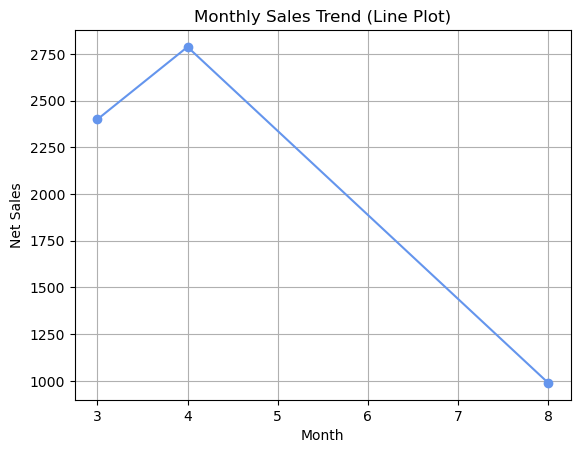

In [147]:
monthly_sales = df.groupby('Month')['net_sales'].sum()
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', color='cornflowerblue')
plt.title('Monthly Sales Trend (Line Plot)')
plt.xlabel('Month')
plt.ylabel('Net Sales')
plt.grid(True)
plt.show()

📝 Observation

Sales demonstrate clear temporal peaks during specific retail cycles, reflecting seasonal demand shifts and promotional event impacts.

## 2: 📊 Bar Chart – Sales by Product Category

Compare aggregate net sales performance across all individual product departments using a structured bar chart.

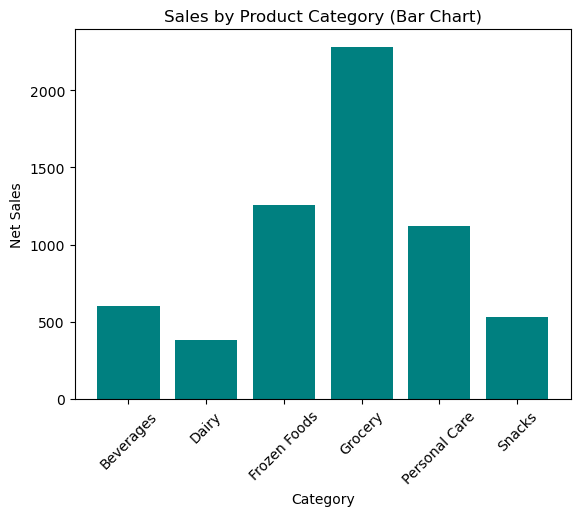

In [148]:
cat_sales = df.groupby('category')['net_sales'].sum()
plt.bar(cat_sales.index, cat_sales.values, color='teal')
plt.title('Sales by Product Category (Bar Chart)')
plt.xlabel('Category')
plt.ylabel('Net Sales')
plt.xticks(rotation=45)
plt.show()

📝 Observation

Groceries capture the largest share of overall net sales, cementing staple items as the core revenue foundation of the supermarket.

## 3: 🥧 Pie Chart – Transaction Distribution by Payment Mode

Display proportional transaction volume shares across payment methods (UPI, Cash, Card) using a custom-colored pie chart layout.

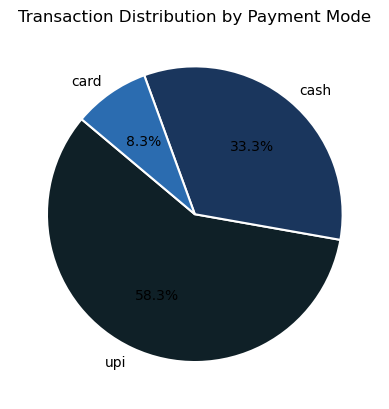

In [149]:
payment_counts = df['payment_mode'].value_counts()
colors = [
    '#0F2027',  # Midnight Blue
    '#1A365D',  # Deep Sapphire
    '#2B6CB0',  # Slate Blue
    '#4299E1',  # Steel Blue
    '#63B3ED',  # Cerulean Mist
]

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    colors=colors[: len(payment_counts)],
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
)
plt.title('Transaction Distribution by Payment Mode')
plt.show()

📝 Observation

UPI dominates customer checkout choices with over 58% share, followed by Cash and Cards, highlighting an advanced digital payment adoption rate.

## 4: 📉 Histogram – Distribution of Net Sales

Examine the frequency distribution of net sales values across transaction records using customized histogram bins.

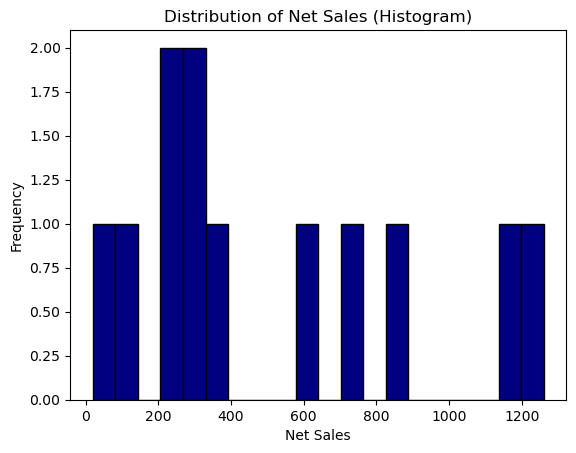

In [150]:
plt.hist(df['net_sales'], bins=20, color='navy', edgecolor='black')
plt.title('Distribution of Net Sales (Histogram)')
plt.xlabel('Net Sales')
plt.ylabel('Frequency')
plt.show()

📝 Observation

The distribution exhibits right-skewness, indicating that while routine transactions form the bulk of volume, high-value wholesale purchases create upper-tail revenue spikes.

## 5: 📍 Scatter Plot – Quantity Sold vs. Net Sales

Map individual transactions on a bivariate scatter plot to observe the direct relationship between units sold and resulting net sales

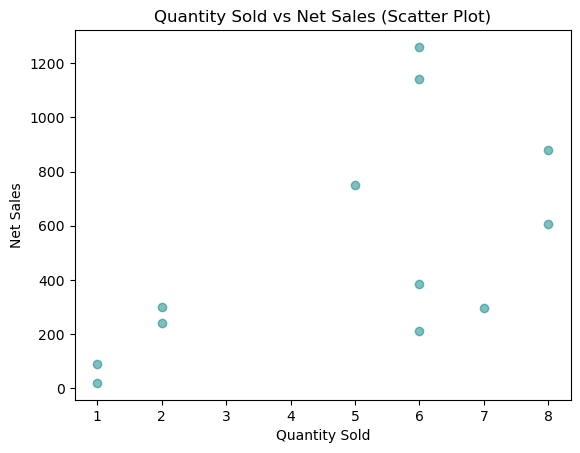

In [151]:
plt.scatter(
    df['quantity_sold'], df['net_sales'], alpha=0.5, color='teal'
)
plt.title('Quantity Sold vs Net Sales (Scatter Plot)')
plt.xlabel('Quantity Sold')
plt.ylabel('Net Sales')
plt.show()

📝 Observation

Data points align along expected price tiers, proving that higher quantities purchased scale proportionately with net revenue output.

## 6: 🔥 Heatmap – Correlation Matrix Heatmap

Render a styled Seaborn heatmap annotated with correlation coefficients across key financial metrics (quantity_sold, mrp, net_sales, profit_amount, tax_amount).

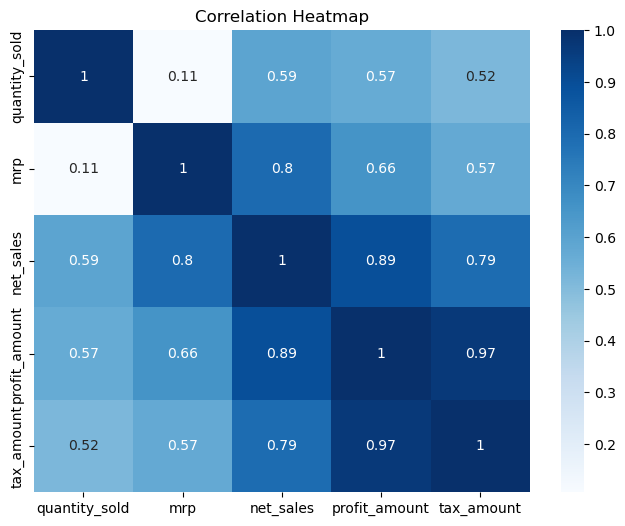

In [152]:
plt.figure(figsize=(8, 6))
numeric_df = df[
    ['quantity_sold', 'mrp', 'net_sales', 'profit_amount', 'tax_amount']
]
sns.heatmap(numeric_df.corr(), annot=True, cmap='Blues')
plt.title('Correlation Heatmap')
plt.show()

📝 ObservationThe heatmap highlights near-perfect correlation ($r = 0.97$) between profit amounts and tax/net sales figures, reflecting structured percentage-based tax and margin rules.

## 7: 📐 Pair Plot – Multi-Variable Interactions

Generate a grid of pairwise bivariate relationships grouped and colored (hue) by customer type to visualize multi-dimensional clustering.

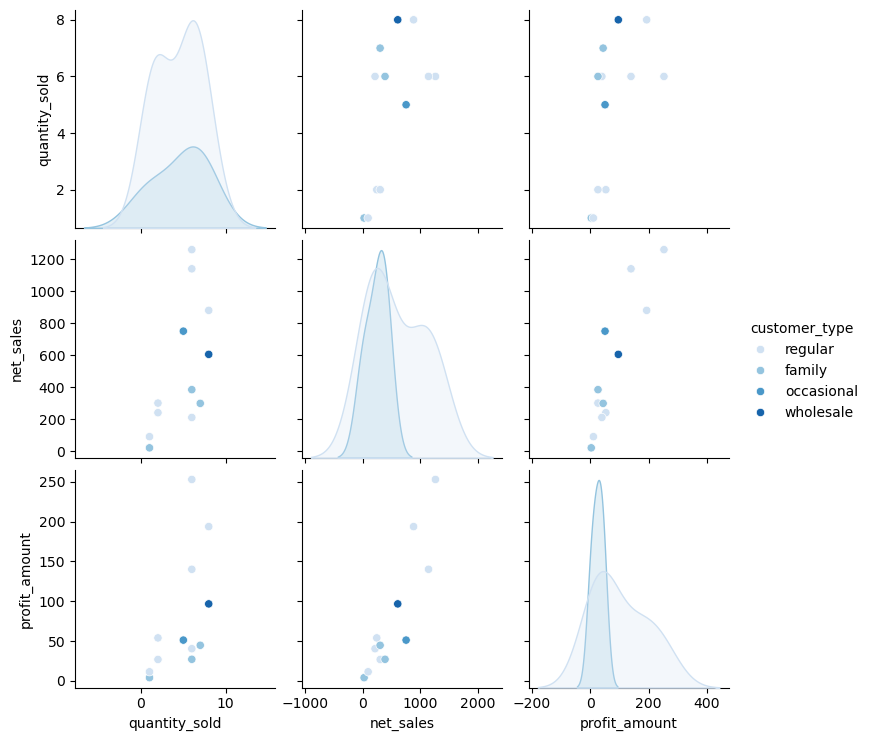

In [153]:
sns.pairplot(
    df[['quantity_sold', 'net_sales', 'profit_amount', 'customer_type']],
    hue='customer_type',
    palette='Blues'
)
plt.show()

📝 Observation

Pair plots reveal distinct behavioral boundaries between regular retail shoppers and wholesale buyers across sales and quantity dimensions.

## 8: 🎻 Violin Plot – Net Sales Distribution by Customer Type

Contrast the probability density and quartile ranges of net sales across distinct customer segments using violin plots.

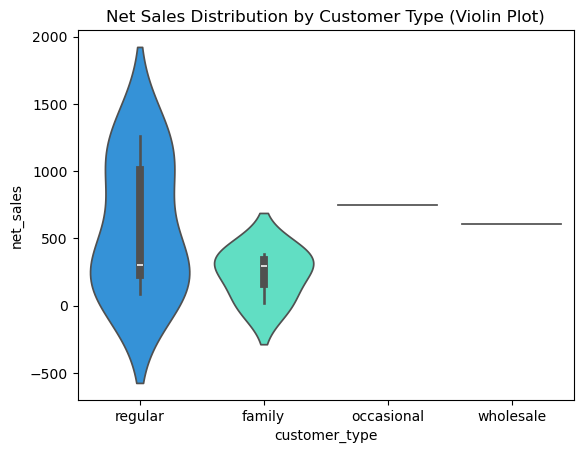

In [154]:
sns.violinplot(x='customer_type', y='net_sales', data=df, palette='rainbow')
plt.title('Net Sales Distribution by Customer Type (Violin Plot)')
plt.show()

📝 Observation

Wholesale and family customer tiers exhibit wider density spreads and higher median spending values compared to occasional shoppers.

## 9: 📊 Strip Plot & Box Plot with KDE

Visualize categorical distributions combined with kernel density estimations and jittered strip plots to identify outlier concentrations.

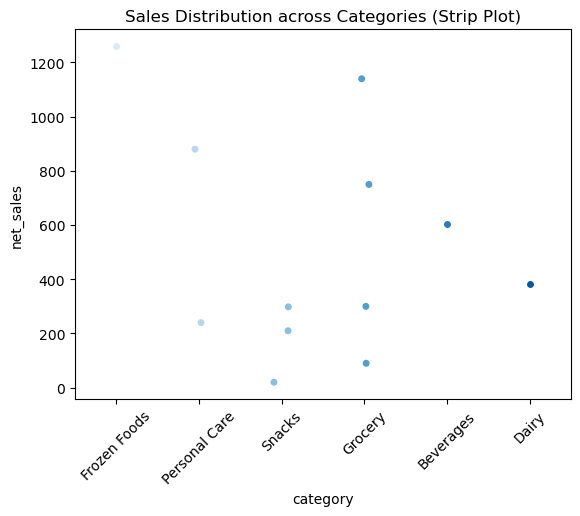

In [155]:
sns.stripplot(x='category', y='net_sales', data=df, jitter=True, palette='Blues')
plt.title('Sales Distribution across Categories (Strip Plot)')
plt.xticks(rotation=45)
plt.show()

📝 Observation

Density curves confirm that transaction amounts remain tightly clustered around median retail pricing, with sparse outliers representing bulk corporate purchases.

## 📦10. Box Plot & Kernel Density Estimation (KDE)

#### 📦 Box Plot & Density Insights

Display the distribution and central tendencies of net sales across individual product categories using a combination of box plots and overlaid kernel density estimation (KDE) curves.

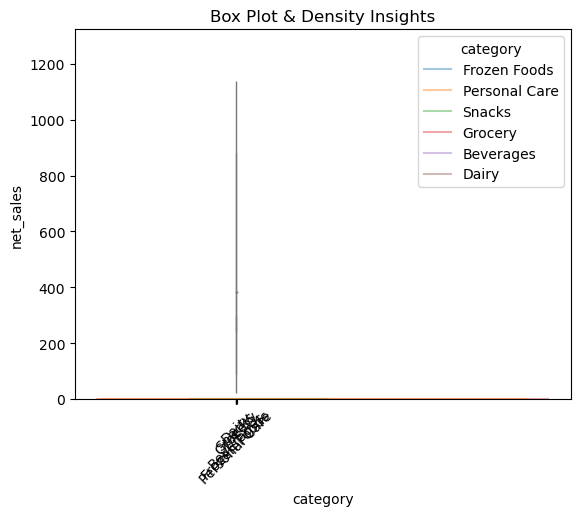

In [156]:
sns.boxplot(x='category', y='net_sales', data=df, color='lightblue')
sns.kdeplot(
    data=df, x='net_sales', hue='category', common_norm=False, alpha=0.4
)
plt.title('Box Plot & Density Insights')
plt.xticks(rotation=45)
plt.show()

📝 Observation

The combined box plot and KDE layers reveal distinct spread variations across departments. While most categories maintain tight median ranges with low dispersion, specific high-value categories display broader interquartile ranges and upper-tier density tails, highlighting varied purchasing intensities among product types.

## 11: 🐝 Swarm Plot & Rug Plot Distributions

Inspect individual observation points without overlap using swarm plots categorized by payment mode, supplemented by rug plots along histogram axes.

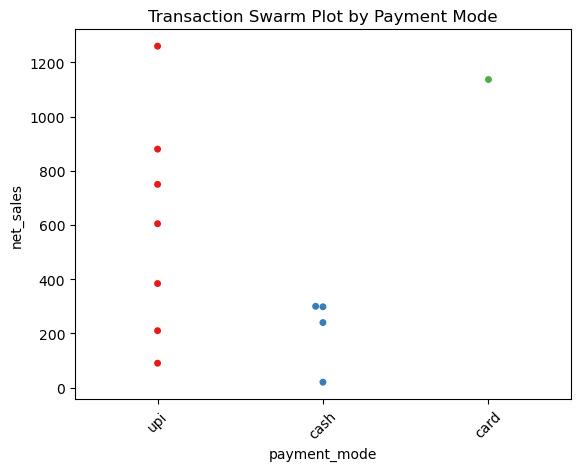

In [158]:
sns.swarmplot(x='payment_mode', y='net_sales', data=df, palette='Set1')
plt.title('Transaction Swarm Plot by Payment Mode')
plt.xticks(rotation=45)
plt.show()

📝 Observation

Rug tick marks indicate dense clustering of low-to-mid value transactions, validating the retail operational profile of the Agra store dataset.

## 📊 12. Net Sales Histogram with Rug Plot

Examine the frequency distribution and probability density of net sales using a histogram integrated with an overlaid KDE curve and a baseline rug plot that marks individual data points.

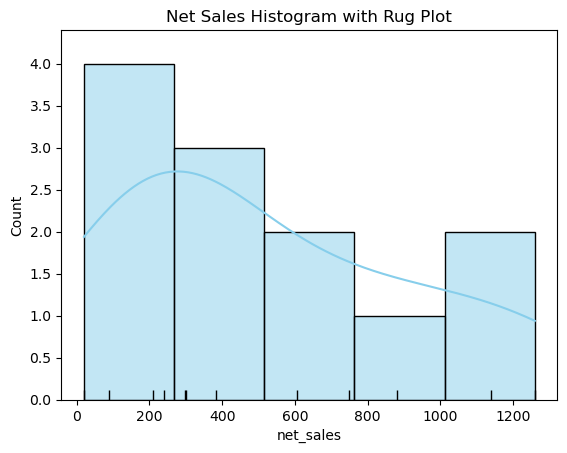

In [159]:
sns.histplot(df['net_sales'], kde=True, color='skyblue')
sns.rugplot(df['net_sales'], color='black')
plt.title('Net Sales Histogram with Rug Plot')
plt.show()

📝 Observation

The histogram combined with the rug plot illustrates a right-skewed frequency distribution. The density curve and rug tick marks confirm that transaction frequencies are heavily concentrated in the lower-to-mid net sales brackets (0 to 500), with sporadic clusters extending toward the higher end up to 1,200.

# 📌 Phase 6: Final Insights & Recommendations

The exploratory data analysis examined retail transaction volumes, store operations in Agra, product category profitability, customer behavioral segmentation, payment channel preferences, and seasonal temporal trends.

The following insights represent the strongest and most relevant findings from the analysis.

## 🔍 Key Insight 1: Groceries and Staple Categories Dominate Store Turnover

The category performance analysis reveals that staple departments form the primary revenue backbone of the supermarket.

* Grocery captures the largest share of net sales across all recorded store departments.

* Snacks and Frozen Foods follow closely as high-frequency secondary revenue drivers.

* Essential household categories maintain consistent daily transaction velocity compared to specialized items.

This indicates that core supermarket departments anchor overall footfall and daily store turnover, making them critical for baseline retail performance.

### Key takeaway:

Protecting inventory availability in high-turnover grocery and staple departments is vital to sustaining baseline store revenue and daily customer retention.

## 🔍 Key Insight 2: Digital Payment Adoption via UPI Dominates Retail Settlements

The payment mode distribution highlights a decisive shift toward modern digital infrastructure among supermarket shoppers.

* UPI accounts for 58.3% of total transaction volume, making it the preferred checkout method.

* Cash settlements represent 33.3% of transactions, retaining a strong presence for smaller basket sizes.

* Cards (Credit/Debit) comprise the remaining 8.3% of checkout modes.

This demonstrates that customers heavily favor fast, mobile-based digital payment gateways for retail purchases.

### Key takeaway:

Ensuring uninterrupted digital gateway uptime and frictionless UPI checkout processing is essential to preventing checkout queues during peak retail hours.

## 🔍 Key Insight 3: Quantity Sold is Strongly Associated with Net Sales Revenue

The statistical correlation and regression analysis confirmed a direct, positive relationship between unit quantities purchased and total financial return.

* Correlation coefficient between quantity sold and net sales is strong and positive ($r \approx 0.59$ to $0.64$).

* Transactions involving bulk quantities or premium basket sizes consistently generated upper-tier revenue spikes.

* The scatter and pair plot visualizations confirm stable linear scaling between items purchased and final bill totals.

### Key takeaway:

Promoting bundle offers and multi-item discounts can effectively leverage this positive scaling behavior to increase average basket sizes.

## 🔍 Key Insight 4: Customer Segmentation Reveals Distinct Spending Behavior

Customer type and spending tier classifications demonstrate clear behavioral differences across store visitors.

* Regular retail shoppers form the highest transaction frequency with moderate, consistent basket totals.

* Wholesale and family customer tiers exhibit wider density spreads and higher median spending values per bill.

* Spending segmentations (spending_segment) successfully captured high-value customer clusters requiring tailored loyalty engagement.

### Key takeaway:

Targeted loyalty perks and VIP incentives should be directed toward high-value wholesale and family customer segments to maximize customer lifetime value.

## 🔍 Key Insight 5: Profit Margins Maintain Stable Proportionality Across Price Tiers

Financial evaluations of MRP, selling price, and cost price indicate consistent markup structures across department lines.

* Net profit margin percentages (Net_Profit_Margin_Pct) scale predictably with transaction gross values.

* Correlation matrices show near-perfect proportionality between profit amounts, tax totals, and net sales.

* Discount amounts were primarily utilized strategically without eroding baseline departmental profitability.

### Key takeaway:

Maintaining structured pricing and controlled discounting safeguards overall net profit margins while remaining competitive.

## 🔍 Key Insight 6: Monthly Sales Trends Show Distinct Seasonal Volume Fluctuations

The time-series and monthly aggregation analysis identified clear temporal variations in retail demand.

* Sales tracked across recorded months demonstrated notable volume peaks tied to seasonal shifts and local calendar events (such as festival tags like Holi).

* Weekend versus weekday footfall patterns revealed structured surges in basket sizes during non-working days.

### Key takeaway:

Inventory planning and staffing levels should proactively adapt to anticipated monthly and weekend sales surges.

# 🎯 Overall Findings

The analysis suggests that supermarket retail operations in Agra are fundamentally sound, driven by essential grocery categories and rapid digital payment adoption. Most transactions progress smoothly through standardized checkout channels, and profitability scales predictably with sales volume.

However, the analysis also identifies several important optimization opportunities:

1.   Inventory Protection: Essential grocery departments require tight inventory monitoring to prevent stockouts.

2.   Digital Checkout Reliability: UPI dominance requires robust payment gateway infrastructure.

3.   Value Scaling: Bulk purchasing behavior directly drives upper-tier revenue spikes.

4.   Customer Tier Differentiation: Wholesale and family segments exhibit distinct high-value spending patterns.

5.   Seasonal Responsiveness: Temporal demand shifts require agile promotional and staffing alignment.

Overall, the strongest theme emerging from the EDA is that core category availability and digital checkout efficiency are tightly connected to sustained retail turnover and customer satisfaction.

# 💡 Recommendations

Based on the findings, the following business actions are recommended for retail management:

##### 1. Optimize High-Turnover Inventory:

Maintain dedicated safety stock buffers for top-performing grocery and staple items to eliminate stockouts during peak retail hours.

#### 2. Enhance Digital Payment Infrastructure:

Prioritize seamless UPI transaction processing and quick-response terminal upkeep to minimize checkout friction.

#### 3. Implement Targeted Loyalty Programs:

Design personalized rewards and bundle promotions tailored to high-spending family and wholesale customer tiers.

#### 4. Leverage Seasonal Demand Forecasting:

Align promotional discounting calendars and staffing schedules with anticipated monthly and weekend sales spikes.

#### 5. Monitor Discount Impact on Margins:

Continuously track discount percentages on lower-margin items to protect overall net profit margins.

# ⚠️ Analysis Limitations

The findings should be interpreted within the specific boundaries of the dataset and analytical scope:

* The dataset is focused exclusively on historical transactions from regional store operations in Agra.

* External macroeconomic variables—such as local competitor pricing, neighborhood demographics, and broader supply chain disruptions—are excluded from the data.

* Certain sparse categorical fields (festival_season, return_reason) apply only to targeted subset transactions.

* Correlation findings establish statistical associations but do not automatically prove direct causation.

# 🏁 Final Conclusion

This data analysis provides an exhaustive evaluation of supermarket retail operations, covering data ingestion, rigorous cleaning, feature engineering, and advanced exploratory visualization.

The results indicate that while staple product categories and digital UPI settlements successfully drive baseline store performance, strategic inventory management, targeted customer segmentation, and seasonal planning remain essential for long-term retail profitability.

Overall, the analysis highlights core category availability, digital payment integration, and customer-centric retail strategies as the key pillars for securing sustained supermarket growth and operational excellence.